In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, matthews_corrcoef
)
warnings.filterwarnings('ignore')

BASE_DIR = Path('../outputs/hybrid')
FIG_DIR = Path('../figures')
TAB_DIR = Path('../tables')
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 150, 'font.size': 11, 'font.family': 'serif',
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

def compute_metrics(y_true, y_score, threshold):
    y_pred = (y_score >= threshold).astype(int)
    if len(np.unique(y_true)) < 2 or len(np.unique(y_pred)) < 2:
        return None
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    return {
        'Accuracy':    round(accuracy_score(y_true, y_pred) * 100, 2),
        'Precision':   round(precision_score(y_true, y_pred, zero_division=0) * 100, 2),
        'Recall':      round(recall_score(y_true, y_pred, zero_division=0) * 100, 2),
        'Specificity': round(tn / (tn + fp) * 100, 2),
        'F1':          round(f1_score(y_true, y_pred, zero_division=0) * 100, 2),
        'MCC':         round(matthews_corrcoef(y_true, y_pred), 4),
        'ROC_AUC':     round(roc_auc_score(y_true, y_score) * 100, 2),
        'PR_AUC':      round(average_precision_score(y_true, y_score) * 100, 2),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }

print("Setup complete.")

Setup complete.


In [2]:
df = pd.read_csv("../outputs/hybrid/final_hybrid_predictions_train_calibrated.csv")

y_true     = df['y_true'].values
xgb_raw    = df['xgb_proba'].values
xgb_cal    = df['calibrated_xgb_proba'].values
vqc_raw    = df['vqc_proba'].values
vqc_cal    = df['calibrated_vqc_proba'].values  
hybrid_cal = df['hybrid_score'].values

from sklearn.metrics import roc_auc_score
print(f"Loaded: {df.shape}")
print(f"Test set: {len(y_true)} samples, {int(y_true.sum())} diabetic ({y_true.mean()*100:.1f}%)")
print(f"Hybrid range:  [{hybrid_cal.min():.4f}, {hybrid_cal.max():.4f}]")
print(f"VQC raw range: [{vqc_raw.min():.4f}, {vqc_raw.max():.4f}]")
print(f"VQC cal range: [{vqc_cal.min():.4f}, {vqc_cal.max():.4f}]")
print(f"XGB raw range: [{xgb_raw.min():.4f}, {xgb_raw.max():.4f}]")
print(f"Hybrid AUC:    {roc_auc_score(y_true, hybrid_cal)*100:.2f}%")
print(f"VQC cal = VQC raw: {np.allclose(vqc_cal, vqc_raw)}")

Loaded: (154, 10)
Test set: 154 samples, 54 diabetic (35.1%)
Hybrid range:  [0.1021, 0.8910]
VQC raw range: [0.2041, 0.7980]
VQC cal range: [0.2041, 0.7980]
XGB raw range: [0.0023, 0.9625]
Hybrid AUC:    88.13%
VQC cal = VQC raw: True


In [3]:

hybrid_raw_score = 0.5 * xgb_raw + 0.5 * vqc_raw
metrics_no_cal = compute_metrics(y_true, hybrid_raw_score, threshold=0.45)
print("Ablation 1: No Calibration (raw probabilities, ω=0.5, t=0.45)")
print(f"  Hybrid raw score range: [{hybrid_raw_score.min():.4f}, {hybrid_raw_score.max():.4f}]")
print()
for k, v in metrics_no_cal.items():
    print(f"  {k}: {v}")

Ablation 1: No Calibration (raw probabilities, ω=0.5, t=0.45)
  Hybrid raw score range: [0.1055, 0.8730]

  Accuracy: 78.57
  Precision: 64.38
  Recall: 87.04
  Specificity: 74.0
  F1: 74.02
  MCC: 0.5833
  ROC_AUC: 88.06
  PR_AUC: 83.25
  TN: 74
  FP: 26
  FN: 7
  TP: 47


In [4]:

metrics_no_quantum = compute_metrics(y_true, xgb_cal, threshold=0.45)
print("Ablation 2: No Quantum Branch (XGBoost only, calibrated, t=0.45)")
for k, v in metrics_no_quantum.items():
    print(f"  {k}: {v}")


metrics_no_quantum_50 = compute_metrics(y_true, xgb_cal, threshold=0.50)
print("\nAblation 2b: No Quantum Branch (XGBoost only, calibrated, t=0.50)")
for k, v in metrics_no_quantum_50.items():
    print(f"  {k}: {v}")

print("\nReference (published standalone XGBoost at t=0.50):")
print("  Acc=81.17%, Recall=79.63%, F1=74.78%, MCC=0.6013, ROC-AUC=87.39%")

Ablation 2: No Quantum Branch (XGBoost only, calibrated, t=0.45)
  Accuracy: 81.17
  Precision: 74.51
  Recall: 70.37
  Specificity: 87.0
  F1: 72.38
  MCC: 0.5817
  ROC_AUC: 87.48
  PR_AUC: 82.4
  TN: 87
  FP: 13
  FN: 16
  TP: 38

Ablation 2b: No Quantum Branch (XGBoost only, calibrated, t=0.50)
  Accuracy: 80.52
  Precision: 74.0
  Recall: 68.52
  Specificity: 87.0
  F1: 71.15
  MCC: 0.5658
  ROC_AUC: 87.48
  PR_AUC: 82.4
  TN: 87
  FP: 13
  FN: 17
  TP: 37

Reference (published standalone XGBoost at t=0.50):
  Acc=81.17%, Recall=79.63%, F1=74.78%, MCC=0.6013, ROC-AUC=87.39%


In [5]:

metrics_default_thr = compute_metrics(y_true, hybrid_cal, threshold=0.50)
print("Ablation 3: Default Threshold (full hybrid score, t=0.50)")
for k, v in metrics_default_thr.items():
    print(f"  {k}: {v}")


print("\nThreshold sensitivity (computed from correct hybrid_cal):")
print(f"  {'Threshold':>10}  {'Accuracy':>9}  {'Recall':>7}  {'Specificity':>12}  {'F1':>7}  {'MCC':>8}")
for thr in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    m = compute_metrics(y_true, hybrid_cal, threshold=thr)
    if m:
        marker = " ← selected" if thr == 0.45 else ""
        print(f"  {thr:>10.2f}  {m['Accuracy']:>9.2f}  {m['Recall']:>7.2f}  "
              f"{m['Specificity']:>12.2f}  {m['F1']:>7.2f}  {m['MCC']:>8.4f}{marker}")

Ablation 3: Default Threshold (full hybrid score, t=0.50)
  Accuracy: 82.47
  Precision: 77.55
  Recall: 70.37
  Specificity: 89.0
  F1: 73.79
  MCC: 0.6082
  ROC_AUC: 88.13
  PR_AUC: 83.04
  TN: 89
  FP: 11
  FN: 16
  TP: 38

Threshold sensitivity (computed from correct hybrid_cal):
   Threshold   Accuracy   Recall   Specificity       F1       MCC
        0.30      74.03    88.89         66.00    70.59    0.5249
        0.35      78.57    88.89         73.00    74.42    0.5908
        0.40      79.87    79.63         80.00    73.50    0.5787
        0.45      83.77    79.63         86.00    77.48    0.6486 ← selected
        0.50      82.47    70.37         89.00    73.79    0.6082
        0.55      83.12    68.52         91.00    74.00    0.6205
        0.60      81.82    64.81         91.00    71.43    0.5896


In [6]:

hybrid_equal = 0.5 * xgb_cal + 0.5 * vqc_cal
metrics_equal = compute_metrics(y_true, hybrid_equal, threshold=0.45)
print("Ablation 4: Equal Fusion Weights (0.5/0.5, calibrated, t=0.45)")
print(f"  Equal-weight hybrid score range: [{hybrid_equal.min():.4f}, {hybrid_equal.max():.4f}]")
print(f"  Baseline hybrid score range:     [{hybrid_cal.min():.4f}, {hybrid_cal.max():.4f}]")
print()
for k, v in metrics_equal.items():
    print(f"  {k}: {v}")


print("\nFusion Weight Sensitivity (calibrated, t=0.45):")
print(f"  {'XGB':>4}  {'VQC':>4}  {'Accuracy':>9}  {'Recall':>7}  {'F1':>7}  {'MCC':>7}  {'ROC_AUC':>9}")
for w_xgb in [0.5, 0.6, 0.7, 0.8]:
    w_vqc = round(1.0 - w_xgb, 1)
    score = w_xgb * xgb_cal + w_vqc * vqc_cal
    m = compute_metrics(y_true, score, threshold=0.45)
    if m:
        marker = ' <-- baseline' if w_xgb == 0.8 else ''
        print(f"  {w_xgb:>4.1f}  {w_vqc:>4.1f}  {m['Accuracy']:>9.2f}  {m['Recall']:>7.2f}  {m['F1']:>7.2f}  {m['MCC']:>7.4f}  {m['ROC_AUC']:>9.2f}{marker}")

Ablation 4: Equal Fusion Weights (0.5/0.5, calibrated, t=0.45)


  Equal-weight hybrid score range: [0.1021, 0.8910]
  Baseline hybrid score range:     [0.1021, 0.8910]

  Accuracy: 83.77
  Precision: 75.44
  Recall: 79.63
  Specificity: 86.0
  F1: 77.48
  MCC: 0.6486
  ROC_AUC: 88.13
  PR_AUC: 83.04
  TN: 86
  FP: 14
  FN: 11
  TP: 43

Fusion Weight Sensitivity (calibrated, t=0.45):
   XGB   VQC   Accuracy   Recall       F1      MCC    ROC_AUC
   0.5   0.5      83.77    79.63    77.48   0.6486      88.13
   0.6   0.4      83.12    75.93    75.93   0.6293      87.93
   0.7   0.3      81.82    72.22    73.58   0.5976      87.94
   0.8   0.2      81.17    70.37    72.38   0.5817      88.22 <-- baseline


In [7]:

metrics_vqc_only = compute_metrics(y_true, vqc_cal, threshold=0.45)
print("Ablation 5: Quantum Branch Only (VQC calibrated, t=0.45)")
print(f"  VQC calibrated range: [{vqc_cal.min():.4f}, {vqc_cal.max():.4f}]")
print()
for k, v in metrics_vqc_only.items():
    print(f"  {k}: {v}")


print("\nVQC calibrated probability by true class:")
mask0 = y_true == 0
mask1 = y_true == 1
print(f"  Non-diabetic (n={mask0.sum()}): mean={vqc_cal[mask0].mean():.4f}, std={vqc_cal[mask0].std():.4f}")
print(f"  Diabetic     (n={mask1.sum()}): mean={vqc_cal[mask1].mean():.4f}, std={vqc_cal[mask1].std():.4f}")
separation = abs(vqc_cal[mask1].mean() - vqc_cal[mask0].mean())
print(f"  Class mean separation: {separation:.4f}")
print(f"  (XGBoost cal separation: {abs(xgb_cal[mask1].mean() - xgb_cal[mask0].mean()):.4f})")

Ablation 5: Quantum Branch Only (VQC calibrated, t=0.45)
  VQC calibrated range: [0.2041, 0.7980]

  Accuracy: 67.53
  Precision: 52.17
  Recall: 88.89
  Specificity: 56.0
  F1: 65.75
  MCC: 0.4368
  ROC_AUC: 84.07
  PR_AUC: 76.64
  TN: 56
  FP: 44
  FN: 6
  TP: 48

VQC calibrated probability by true class:
  Non-diabetic (n=100): mean=0.4223, std=0.1207
  Diabetic     (n=54): mean=0.5839, std=0.1177
  Class mean separation: 0.1616
  (XGBoost cal separation: 0.5228)


In [8]:

def evaluate_risk_stratification(scores, y_true, low_pct, high_pct, name):
    low_cut  = np.percentile(scores, low_pct)
    high_cut = np.percentile(scores, high_pct)

    risk = np.where(scores < low_cut, 'Low',
           np.where(scores < high_cut, 'Moderate', 'High'))

    results = []
    for grp in ['Low', 'Moderate', 'High']:
        mask = risk == grp
        if mask.sum() > 0:
            results.append({
                'Configuration':   name,
                'Risk Group':      grp,
                'N':               int(mask.sum()),
                'Diabetes Rate (%)': round(y_true[mask].mean() * 100, 1),
                'Low Cutoff':      round(low_cut, 4),
                'High Cutoff':     round(high_cut, 4),
            })
    return pd.DataFrame(results)


df_tertile  = evaluate_risk_stratification(hybrid_cal, y_true, 33.3, 66.7, 'Tertile (33/66)')
df_quartile = evaluate_risk_stratification(hybrid_cal, y_true, 25.0, 75.0, 'Quartile (25/75)')
df_strat    = pd.concat([df_tertile, df_quartile], ignore_index=True)

print("Risk Stratification Sensitivity Analysis:")
print(df_strat.to_string(index=False))

print(f"\nPopulation diabetes prevalence (reference): {y_true.mean()*100:.1f}%")
print("\nInterpretation:")
for cfg in ['Tertile (33/66)', 'Quartile (25/75)']:
    sub = df_strat[df_strat['Configuration'] == cfg]
    low_rate  = sub.loc[sub['Risk Group'] == 'Low',  'Diabetes Rate (%)'].values
    high_rate = sub.loc[sub['Risk Group'] == 'High', 'Diabetes Rate (%)'].values
    if len(low_rate) > 0 and len(high_rate) > 0:
        fold = high_rate[0] / low_rate[0] if low_rate[0] > 0 else float('inf')
        print(f"  {cfg}: Low={low_rate[0]:.1f}%, High={high_rate[0]:.1f}%, "
              f"High/Low ratio={fold:.1f}x")

df_strat.to_csv(TAB_DIR / 'risk_stratification_sensitivity.csv', index=False)
print("\nSaved: risk_stratification_sensitivity.csv")

Risk Stratification Sensitivity Analysis:
   Configuration Risk Group  N  Diabetes Rate (%)  Low Cutoff  High Cutoff
 Tertile (33/66)        Low 51                5.9      0.2294       0.4746
 Tertile (33/66)   Moderate 52               21.2      0.2294       0.4746
 Tertile (33/66)       High 51               78.4      0.2294       0.4746
Quartile (25/75)        Low 39                5.1      0.2095       0.6455
Quartile (25/75)   Moderate 76               27.6      0.2095       0.6455
Quartile (25/75)       High 39               79.5      0.2095       0.6455

Population diabetes prevalence (reference): 35.1%

Interpretation:
  Tertile (33/66): Low=5.9%, High=78.4%, High/Low ratio=13.3x
  Quartile (25/75): Low=5.1%, High=79.5%, High/Low ratio=15.6x

Saved: risk_stratification_sensitivity.csv


Baseline PR_AUC: 83.04%
Master Ablation Table:
                    Configuration  Accuracy  Recall    F1    MCC  ROC_AUC  PR_AUC
           Full Hybrid (Baseline)     83.77   79.63 77.48 0.6486    88.13   83.04
       No Calibration (raw probs)     78.57   87.04 74.02 0.5833    88.06   83.25
No Quantum (XGBoost only, t=0.45)     81.17   70.37 72.38 0.5817    87.48   82.40
No Quantum (XGBoost only, t=0.50)     80.52   68.52 71.15 0.5658    87.48   82.40
       No Threshold Opt. (t=0.50)     82.47   70.37 73.79 0.6082    88.13   83.04
          Equal Weights (0.5/0.5)     83.77   79.63 77.48 0.6486    88.13   83.04
                         VQC Only     67.53   88.89 65.75 0.4368    84.07   76.64

Saved: ablation_study_results.csv


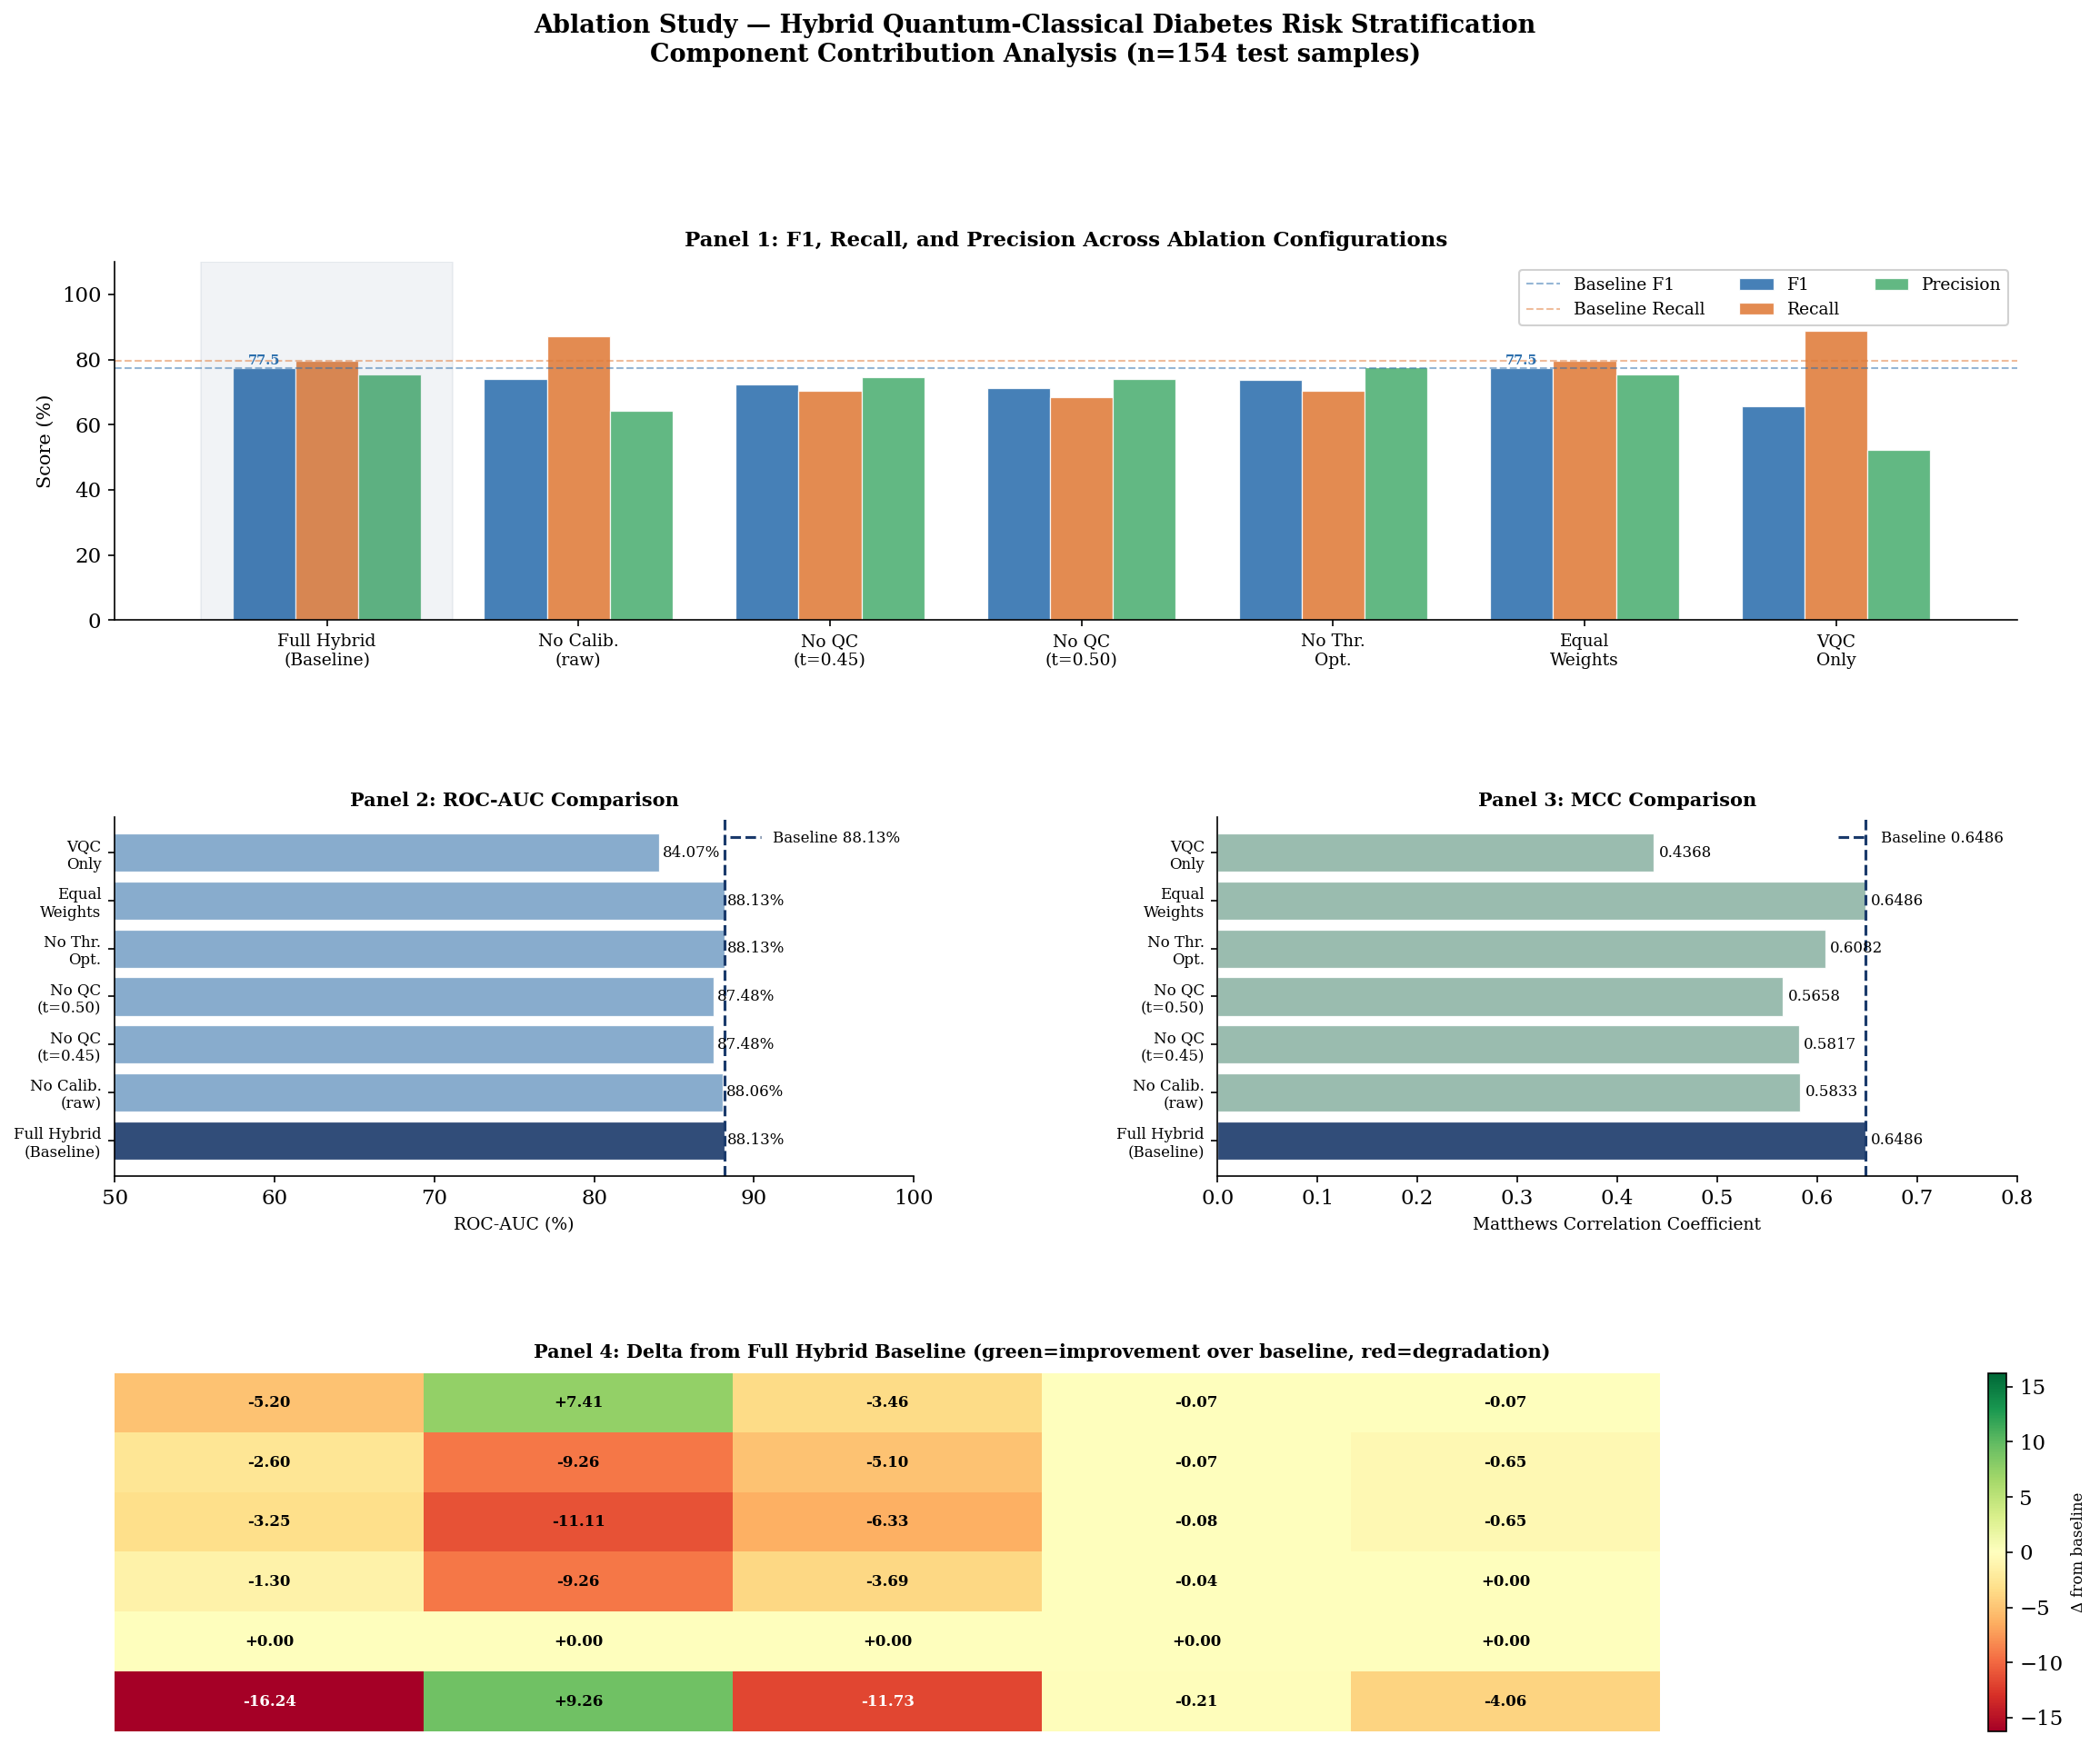

Saved: ablation_01_comprehensive_comparison.png


In [9]:

BASELINE = {
    'Configuration': 'Full Hybrid (Baseline)',
    'Accuracy':    83.77, 'Precision': 75.44, 'Recall':    79.63,
    'Specificity': 86.00, 'F1':        77.48, 'MCC':       0.6486,
    'ROC_AUC':     88.13, 'PR_AUC':    None,
    'Description': 'XGB calibrated (quantile) + VQC raw, ω=0.5, τ=0.45'
}

from sklearn.metrics import average_precision_score


BASELINE['PR_AUC'] = round(
    average_precision_score(y_true, hybrid_cal) * 100, 2
)
print(f"Baseline PR_AUC: {BASELINE['PR_AUC']}%")

def metrics_to_row(name, metrics, desc):
    if metrics is None:
        return {'Configuration': name, 'Description': desc}
    return {
        'Configuration': name,
        'Description':   desc,
        'Accuracy':      metrics['Accuracy'],
        'Precision':     metrics['Precision'],
        'Recall':        metrics['Recall'],
        'Specificity':   metrics['Specificity'],
        'F1':            metrics['F1'],
        'MCC':           metrics['MCC'],
        'ROC_AUC':       metrics['ROC_AUC'],
        'PR_AUC':        metrics['PR_AUC'],
    }

ablation_rows = [
    BASELINE,
    metrics_to_row('No Calibration (raw probs)',
               metrics_no_cal,
               'XGB=0.5, VQC=0.5, raw proba, t=0.45'),
    metrics_to_row('No Quantum (XGBoost only, t=0.45)',
                   metrics_no_quantum,
                   'XGB=1.0, VQC=0.0, calibrated, t=0.45'),
    metrics_to_row('No Quantum (XGBoost only, t=0.50)',
                   metrics_no_quantum_50,
                   'XGB=1.0, VQC=0.0, calibrated, t=0.50'),
    metrics_to_row('No Threshold Opt. (t=0.50)',
                   metrics_default_thr,
                   'XGB=0.8, VQC=0.2, calibrated, t=0.50'),
    metrics_to_row('Equal Weights (0.5/0.5)',
                   metrics_equal,
                   'XGB=0.5, VQC=0.5, calibrated, t=0.45'),
    metrics_to_row('VQC Only',
                   metrics_vqc_only,
                   'XGB=0.0, VQC=1.0, calibrated, t=0.45'),
]

df_ablation = pd.DataFrame(ablation_rows)
display_cols = ['Configuration', 'Accuracy', 'Recall', 'F1', 'MCC', 'ROC_AUC', 'PR_AUC']
print("Master Ablation Table:")
print(df_ablation[display_cols].to_string(index=False))
df_ablation.to_csv(TAB_DIR / 'ablation_study_results.csv', index=False)
print("\nSaved: ablation_study_results.csv")


numeric_rows = df_ablation.dropna(subset=['Accuracy'])
configs = numeric_rows['Configuration'].tolist()
x = np.arange(len(configs))


bar_colors = ['#1a3a6b'] + ['#6b8cba'] * (len(configs) - 1)
bar_colors[0] = '#1a3a6b'   # Baseline: deep navy

fig = plt.figure(figsize=(18, 14))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.55, wspace=0.38)


ax1 = fig.add_subplot(gs[0, :])
width = 0.25
x_pos = np.arange(len(configs))

f1_vals      = numeric_rows['F1'].tolist()
recall_vals  = numeric_rows['Recall'].tolist()
prec_vals    = numeric_rows['Precision'].tolist()

bars_f1   = ax1.bar(x_pos - width, f1_vals,     width, label='F1',        color='#2c6fad', alpha=0.88, edgecolor='white', lw=0.6)
bars_rec  = ax1.bar(x_pos,         recall_vals,  width, label='Recall',    color='#e07b39', alpha=0.88, edgecolor='white', lw=0.6)
bars_prec = ax1.bar(x_pos + width, prec_vals,    width, label='Precision', color='#4caf72', alpha=0.88, edgecolor='white', lw=0.6)


for bar, val in zip(bars_f1, f1_vals):
    if val == f1_vals[0]:
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}', ha='center', va='bottom', fontsize=7, color='#2c6fad', fontweight='bold')

short_labels = [
    'Full Hybrid\n(Baseline)', 'No Calib.\n(raw)', 'No QC\n(t=0.45)',
    'No QC\n(t=0.50)', 'No Thr.\nOpt.', 'Equal\nWeights', 'VQC\nOnly'
]
ax1.set_xticks(x_pos)
ax1.set_xticklabels(short_labels[:len(configs)], fontsize=9)
ax1.set_ylabel('Score (%)', fontsize=10)
ax1.set_title('Panel 1: F1, Recall, and Precision Across Ablation Configurations',
              fontweight='bold', fontsize=11, pad=8)
ax1.set_ylim(0, 110)
ax1.axhline(77.48, color='#2c6fad', ls='--', lw=1.0, alpha=0.5, label='Baseline F1')
ax1.axhline(79.63, color='#e07b39', ls='--', lw=1.0, alpha=0.5, label='Baseline Recall')
ax1.legend(fontsize=9, frameon=True, framealpha=0.9, loc='upper right', ncol=3)


ax1.axvspan(-0.5, 0.5, alpha=0.06, color='#1a3a6b')

ax2 = fig.add_subplot(gs[1, 0])
roc_vals = numeric_rows['ROC_AUC'].tolist()
bar_c2 = ['#1a3a6b'] + ['#7ba3c8'] * (len(roc_vals) - 1)
bars2 = ax2.barh(x_pos, roc_vals, color=bar_c2, edgecolor='white', lw=0.6, alpha=0.9)
ax2.axvline(88.13, color='#1a3a6b', ls='--', lw=1.5, label='Baseline 88.13%')
ax2.set_yticks(x_pos)
ax2.set_yticklabels(short_labels[:len(configs)], fontsize=8)
ax2.set_xlabel('ROC-AUC (%)', fontsize=9)
ax2.set_title('Panel 2: ROC-AUC Comparison', fontweight='bold', fontsize=10, pad=6)
ax2.set_xlim(50, 100)
for bar, val in zip(bars2, roc_vals):
    ax2.text(val + 0.2, bar.get_y() + bar.get_height()/2,
             f'{val:.2f}%', va='center', fontsize=8)
ax2.legend(fontsize=8, frameon=False)


ax3 = fig.add_subplot(gs[1, 1])
mcc_vals = numeric_rows['MCC'].tolist()
bar_c3 = ['#1a3a6b'] + ['#8fb5a6'] * (len(mcc_vals) - 1)
bars3 = ax3.barh(x_pos, mcc_vals, color=bar_c3, edgecolor='white', lw=0.6, alpha=0.9)
ax3.axvline(0.6486, color='#1a3a6b', ls='--', lw=1.5, label='Baseline 0.6486')
ax3.set_yticks(x_pos)
ax3.set_yticklabels(short_labels[:len(configs)], fontsize=8)
ax3.set_xlabel('Matthews Correlation Coefficient', fontsize=9)
ax3.set_title('Panel 3: MCC Comparison', fontweight='bold', fontsize=10, pad=6)
ax3.set_xlim(0, 0.80)
for bar, val in zip(bars3, mcc_vals):
    ax3.text(val + 0.005, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=8)
ax3.legend(fontsize=8, frameon=False)


ax4 = fig.add_subplot(gs[2, :])
ax4.axis('off')

delta_metrics = ['Accuracy', 'Recall', 'F1', 'MCC', 'ROC_AUC', 'PR_AUC']
baseline_ref  = {'Accuracy': 83.77, 'Recall': 79.63, 'F1': 77.48,
                 'MCC': 0.6486, 'ROC_AUC': 88.13, 'PR_AUC': None}

delta_data = []
delta_labels = []
for _, row in numeric_rows.iterrows():
    if row['Configuration'] == 'Full Hybrid (Baseline)':
        continue
    deltas = []
    for m in delta_metrics:
        try:
            deltas.append(round(row[m] - baseline_ref[m], 2))
        except Exception:
            deltas.append(np.nan)
    delta_data.append(deltas)
    cfg = row['Configuration']
    delta_labels.append(cfg[:30] + ('...' if len(cfg) > 30 else ''))

if delta_data:
    delta_arr = np.array(delta_data, dtype=float)
    vmax = max(abs(np.nanmin(delta_arr)), abs(np.nanmax(delta_arr)), 1.0)

    im = ax4.imshow(delta_arr, cmap='RdYlGn', aspect='auto',
                    vmin=-vmax, vmax=vmax)

    ax4.set_xticks(range(len(delta_metrics)))
    ax4.set_xticklabels([f'Δ {m}' for m in delta_metrics], fontsize=9, fontweight='bold')
    ax4.set_yticks(range(len(delta_labels)))
    ax4.set_yticklabels(delta_labels, fontsize=8)
    ax4.set_title(
        'Panel 4: Delta from Full Hybrid Baseline (green=improvement over baseline, red=degradation)',
        fontweight='bold', fontsize=10, pad=8
    )

    for i in range(len(delta_labels)):
        for j in range(len(delta_metrics)):
            val = delta_arr[i, j]
            if not np.isnan(val):
                txt_color = 'black' if abs(val) < vmax * 0.7 else 'white'
                ax4.text(j, i, f'{val:+.2f}', ha='center', va='center',
                         fontsize=8, color=txt_color, fontweight='bold')

    cbar = plt.colorbar(im, ax=ax4, fraction=0.015, pad=0.01)
    cbar.set_label('Δ from baseline', fontsize=8)

fig.suptitle(
    'Ablation Study — Hybrid Quantum-Classical Diabetes Risk Stratification\n'
    'Component Contribution Analysis (n=154 test samples)',
    fontsize=13, fontweight='bold', y=1.01
)

plt.savefig(FIG_DIR / 'ablation_01_comprehensive_comparison.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: ablation_01_comprehensive_comparison.png")

Component Contribution Table (Δ from Full Hybrid Baseline):
  Negative values = removing this component HURTS performance
  Positive values = removing this component IMPROVES performance

                    Configuration  Δ Accuracy  Δ Recall   Δ F1  Δ MCC  Δ ROC_AUC
       No Calibration (raw probs)       -5.20      7.41  -3.46  -0.07      -0.07
No Quantum (XGBoost only, t=0.45)       -2.60     -9.26  -5.10  -0.07      -0.65
No Quantum (XGBoost only, t=0.50)       -3.25    -11.11  -6.33  -0.08      -0.65
       No Threshold Opt. (t=0.50)       -1.30     -9.26  -3.69  -0.04       0.00
          Equal Weights (0.5/0.5)        0.00      0.00   0.00   0.00       0.00
                         VQC Only      -16.24      9.26 -11.73  -0.21      -4.06

Saved: component_contributions.csv


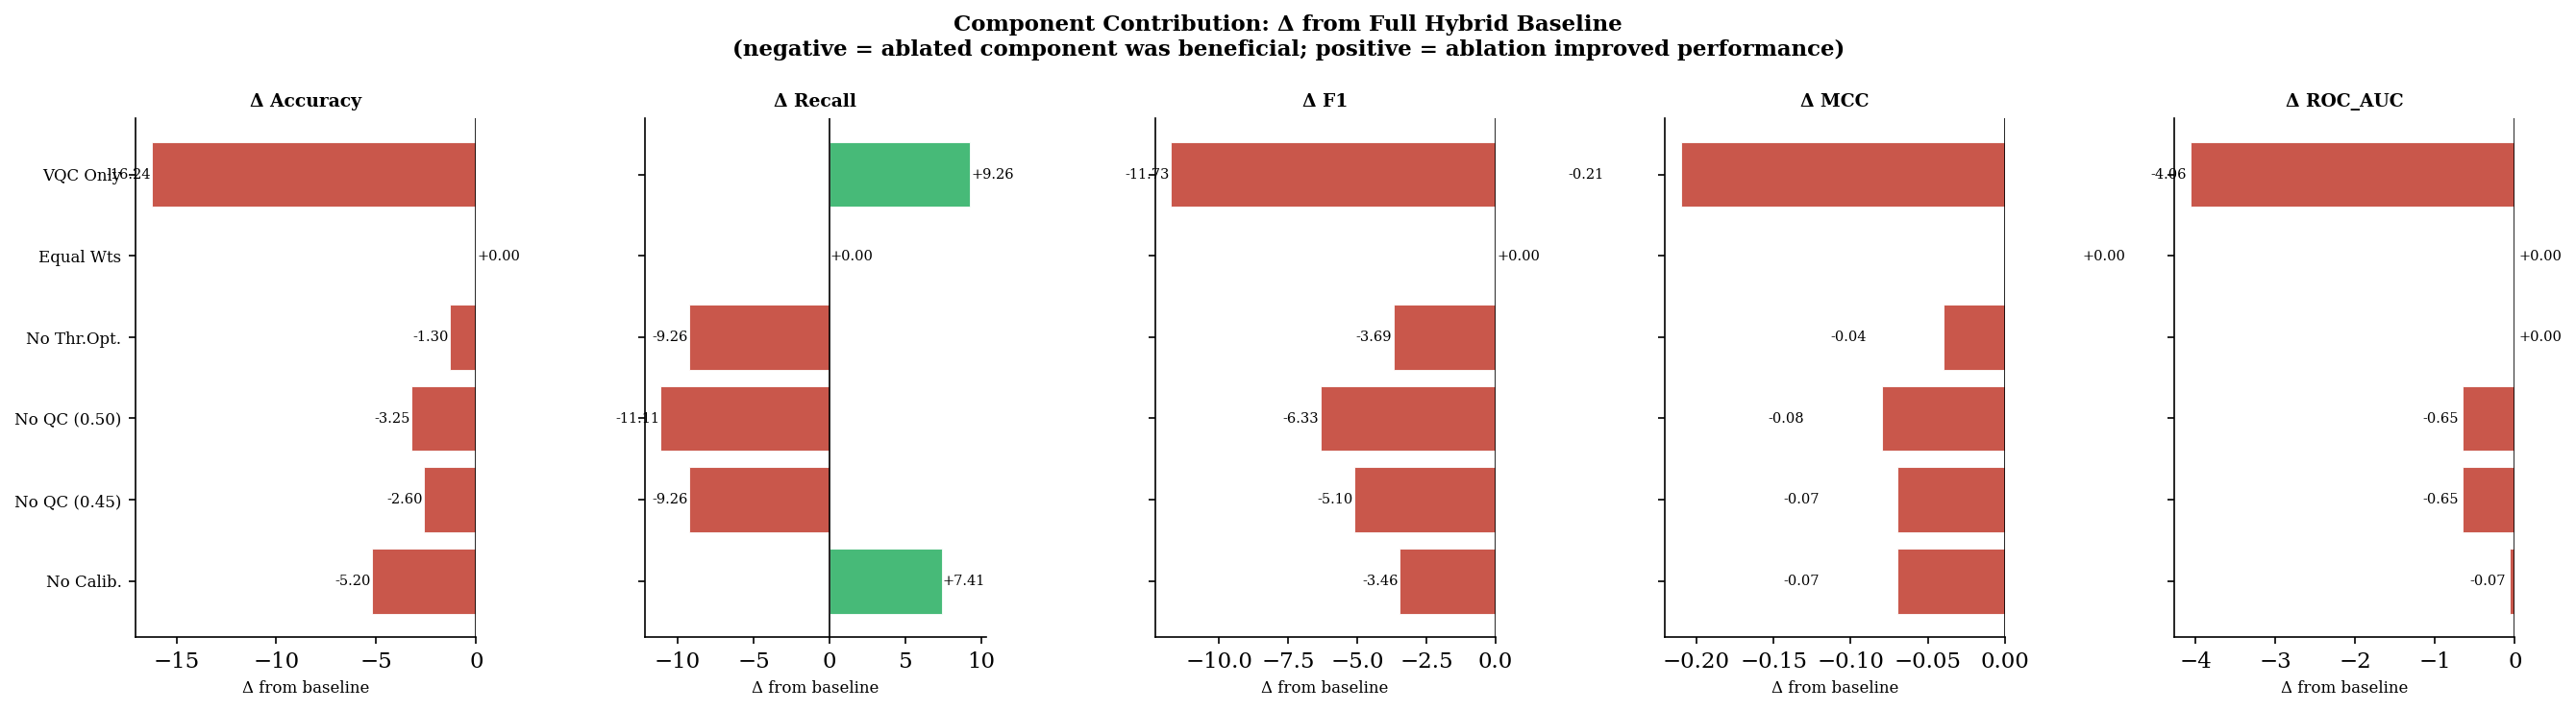

Saved: ablation_02_component_contributions.png


In [10]:
metrics_of_interest = ['Accuracy', 'Recall', 'F1', 'MCC', 'ROC_AUC']
baseline_vals = {'Accuracy': 83.77, 'Recall': 79.63, 'F1': 77.48,
                 'MCC': 0.6486, 'ROC_AUC': 88.13}

contrib_rows = []
for _, row in df_ablation.iterrows():
    if row['Configuration'] == 'Full Hybrid (Baseline)':
        continue
    delta_row = {'Configuration': row['Configuration']}
    for m in metrics_of_interest:
        try:
            delta = row[m] - baseline_vals[m]
            delta_row[f'Δ {m}'] = round(delta, 2)
        except Exception:
            delta_row[f'Δ {m}'] = 'N/A'
    contrib_rows.append(delta_row)

df_contrib = pd.DataFrame(contrib_rows)
print("Component Contribution Table (Δ from Full Hybrid Baseline):")
print("  Negative values = removing this component HURTS performance")
print("  Positive values = removing this component IMPROVES performance")
print()
print(df_contrib.to_string(index=False))
df_contrib.to_csv(TAB_DIR / 'component_contributions.csv', index=False)
print("\nSaved: component_contributions.csv")


fig, axes = plt.subplots(1, len(metrics_of_interest), figsize=(18, 5), sharey=True)
fig.suptitle(
    'Component Contribution: Δ from Full Hybrid Baseline\n'
    '(negative = ablated component was beneficial; positive = ablation improved performance)',
    fontsize=11, fontweight='bold'
)

configs_list = df_contrib['Configuration'].tolist()
short_map = {
    'No Calibration (raw probs)':         'No Calib.',
    'No Quantum (XGBoost only, t=0.45)':  'No QC (0.45)',
    'No Quantum (XGBoost only, t=0.50)':  'No QC (0.50)',
    'No Threshold Opt. (t=0.50)':         'No Thr.Opt.',
    'Equal Weights (0.5/0.5)':            'Equal Wts',
    'VQC Only':                           'VQC Only',
}
y_labels = [short_map.get(c, c[:15]) for c in configs_list]

for ax, metric in zip(axes, metrics_of_interest):
    col = f'Δ {metric}'
    vals = []
    for v in df_contrib[col]:
        try:
            vals.append(float(v))
        except Exception:
            vals.append(0.0)

    colors_bar = ['#c0392b' if v < 0 else '#27ae60' for v in vals]
    ax.barh(range(len(vals)), vals, color=colors_bar, edgecolor='white', lw=0.5, alpha=0.85)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(range(len(y_labels)))
    ax.set_yticklabels(y_labels, fontsize=8)
    ax.set_title(f'Δ {metric}', fontweight='bold', fontsize=9)
    ax.set_xlabel('Δ from baseline', fontsize=8)

    for i, val in enumerate(vals):
        ax.text(val + (0.05 if val >= 0 else -0.05), i,
                f'{val:+.2f}', va='center',
                ha='left' if val >= 0 else 'right',
                fontsize=7)

plt.tight_layout()
plt.savefig(FIG_DIR / 'ablation_02_component_contributions.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: ablation_02_component_contributions.png")